# BÁO CÁO CUỐI KỲ — ADY201m
## Phân loại nhãn Tiền tiểu đường / Tiểu đường trong khảo sát BRFSS 2015 ở người từ 60 tuổi trở lên
**Nhóm 6 — Lớp AI2104**

| Thành viên | Mã sinh viên | Vai trò |
|---|---|---|
| Trần Tuấn Hiệp | HE211144 | Trưởng nhóm — Phát biểu bài toán, tiền xử lý & kiểm định VIF |
| Nguyễn Thế Hải | HE211655 | Thành viên — Phân tích EDA, truy vấn SQL & trực quan hóa |
| Trần Công Du | HE211007 | Thành viên — Kỹ nghệ đặc trưng, Cross-Validation & Đánh giá mô hình |

Báo cáo kết nối toàn diện: xác định bài toán y tế cộng đồng, dữ liệu khảo sát thô, tiền xử lý sạch sẽ, truy vấn SQL nghiệp vụ, phân tích trực quan EDA, kiểm định VIF và so sánh các mô hình học máy (XGBoost, Random Forest, Logistic Regression, Decision Tree) qua 5-Fold Cross-Validation và đánh giá độc lập trên tập Test.


# I. Vấn đề và phương pháp nghiên cứu

### 1. Bối cảnh nghiệp vụ y tế (Business & Clinical Context)
- **Đối tượng nghiên cứu:** Nhóm người cao tuổi từ **60 tuổi trở lên** (mã `_AGEG5YR` từ 9 đến 13 trong khảo sát BRFSS 2015). Đây là nhóm dân số có nguy cơ kháng insulin và mắc bệnh tim mạch - chuyển hóa cao nhất.
- **Mục tiêu ứng dụng:** Xây dựng công cụ phân loại nguy cơ **không xâm lấn**, chi phí thấp dựa trên các câu hỏi khảo sát hành vi và bệnh lý nền để hỗ trợ sàng lọc sơ bộ tại các trạm y tế cộng đồng trong thời gian chờ xét nghiệm máu lâm sàng ($HbA1c$).
- **Ưu tiên chỉ số Recall:** Trong sàng lọc y tế, sai lầm bỏ sót bệnh nhân (*False Negative*) dẫn đến nguy cơ biến chứng nguy hiểm (đột quỵ, suy thận). Do đó, nhóm đặt mục tiêu tối thượng là **Recall > 70%** và tối ưu hóa **Average Precision (AP / PR-AUC)**, chấp nhận đánh đổi một phần Precision ở mức hợp lý.

### 2. Hai câu hỏi nghiên cứu cốt lõi (Research Questions)
1. **RQ1:** Mô hình học máy dựa trên các yếu tố hành vi và bệnh lý nền có thể đạt độ nhạy (Recall) trên $70\%$ trong việc phát hiện ca mắc tiền tiểu đường/tiểu đường ở người cao tuổi hay không?
2. **RQ2:** Việc bổ sung các biến tương tác lâm sàng (như đồng mắc huyết áp cao - mỡ máu cao, hoặc sức khỏe suy giảm kèm khó khăn vận động) có cải thiện đáng kể năng lực phân loại của mô hình hay không?


# II. Nguồn dữ liệu và Khám phá ban đầu

Dữ liệu được trích xuất từ hệ thống giám sát yếu tố nguy cơ hành vi **BRFSS năm 2015** (Behavioral Risk Factor Surveillance System) của CDC Hoa Kỳ. Toàn bộ khảo sát ban đầu gồm hơn 400.000 hồ sơ với 330 cột điều tra.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Đọc file dữ liệu khảo sát BRFSS 2015
df_raw = pd.read_csv('data.csv', float_precision='round_trip')
print(f"Kích thước tệp dữ liệu thô: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")


Kích thước tệp dữ liệu thô: 202,412 dòng × 330 cột


In [1]:
# Bảng 1: Hiển thị 5 dòng đầu tiên của dữ liệu thô
display(df_raw.head())


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNCR,CHCOCNCR,CHCCOPD1,HAVARTH3,ADDEPEV2,CHCKIDNY,DIABETE3,DIABAGE2,SEX,MARITAL,EDUCA,RENTHOM1,NUMHHOL2,NUMPHON2,CPDEMO1,VETERAN3,EMPLOY1,CHILDREN,INCOME2,INTERNET,WEIGHT2,HEIGHT3,PREGNANT,QLACTLM2,USEEQUIP,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,SMOKE100,SMOKDAY2,STOPSMK2,LASTSMK2,USENOW3,ALCDAY5,AVEDRNK2,DRNK3GE5,MAXDRNKS,FRUITJU1,FRUIT1,FVBEANS,FVGREEN,FVORANG,VEGETAB1,EXERANY2,EXRACT11,EXEROFT1,EXERHMM1,EXRACT21,EXEROFT2,EXERHMM2,STRENGTH,LMTJOIN3,ARTHDIS2,ARTHSOCL,JOINPAIN,SEATBELT,FLUSHOT6,FLSHTMY2,IMFVPLAC,PNEUVAC3,HIVTST6,HIVTSTD3,WHRTST10,PDIABTST,PREDIAB1,INSULIN,BLDSUGAR,FEETCHK2,DOCTDIAB,CHKHEMO3,FEETCHK,EYEEXAM,DIABEYE,DIABEDU,PAINACT2,QLMENTL2,QLSTRES2,QLHLTH2,CAREGIV1,CRGVREL1,CRGVLNG1,CRGVHRS1,CRGVPRB1,CRGVPERS,CRGVHOUS,CRGVMST2,CRGVEXPT,VIDFCLT2,VIREDIF3,VIPRFVS2,VINOCRE2,VIEYEXM2,VIINSUR2,VICTRCT4,VIGLUMA2,VIMACDG2,CIMEMLOS,CDHOUSE,CDASSIST,CDHELP,CDSOCIAL,CDDISCUS,WTCHSALT,LONGWTCH,DRADVISE,ASTHMAGE,ASATTACK,ASERVIST,ASDRVIST,ASRCHKUP,ASACTLIM,ASYMPTOM,ASNOSLEP,ASTHMED3,ASINHALR,HAREHAB1,STREHAB1,CVDASPRN,ASPUNSAF,RLIVPAIN,RDUCHART,RDUCSTRK,ARTTODAY,ARTHWGT,ARTHEXER,ARTHEDU,TETANUS,HPVADVC2,HPVADSHT,SHINGLE2,HADMAM,HOWLONG,HADPAP2,LASTPAP2,HPVTEST,HPLSTTST,HADHYST2,PROFEXAM,LENGEXAM,BLDSTOOL,LSTBLDS3,HADSIGM3,HADSGCO1,LASTSIG3,PCPSAAD2,PCPSADI1,PCPSARE1,PSATEST1,PSATIME,PCPSARS1,PCPSADE1,PCDMDECN,SCNTMNY1,SCNTMEL1,SCNTPAID,SCNTWRK1,SCNTLPAD,SCNTLWK1,SXORIENT,TRNSGNDR,RCSGENDR,RCSRLTN2,CASTHDX2,CASTHNO2,EMTSUPRT,LSATISFY,ADPLEASR,ADDOWN,ADSLEEP,ADENERGY,ADEAT1,ADFAIL,ADTHINK,ADMOVE,MISTMNT,ADANXEV,QSTVER,QSTLANG,EXACTOT1,EXACTOT2,MSCODE,_STSTR,_STRWT,_RAWRAKE,_WT2RAKE,_CHISPNC,_CRACE1,_CPRACE,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPWT,_RFHLTH,_HCVU651,_RFHYPE5,_CHOLCHK,_RFCHOL,_MICHD,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR1,_PRACE1,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACE_G1,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG,_SMOKER3,_RFSMOK3,DRNKANY5,DROCDY3_,_RFBING5,_DRNKWEK,_RFDRHV5,FTJUDA1_,FRUTDA1_,BEANDAY_,GRENDAY_,ORNGDAY_,VEGEDA1_,_MISFRTN,_MISVEGN,_FRTRESP,_VEGRESP,_FRUTSUM,_VEGESUM,_FRTLT1,_VEGLT1,_FRT16,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,1.0,1.0,1292015,1,29,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,15.0,18.0,10.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,3.0,NaN,2.0,1.0,4.0,1.0,2.0,NaN,1.0,2.0,8.0,88.0,3.0,2.0,280.0,510.0,NaN,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,3.0,NaN,2.0,3.0,888.0,NaN,NaN,NaN,305.0,310.0,320.0,310.0,305.0,101.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,888.0,1.0,1.0,1.0,6.0,1.0,1.0,112014.0,1.0,1.0,1.0,NaN,NaN,1.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,1.0,NaN,NaN,3.0,11011.0,28.78156,3.0,86.344681,NaN,NaN,NaN,NaN,1.0,0.614125,341.384853,2.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,9.0,1.0,63.0,5.0,70.0,178.0,12701.0,4018.0,4.0,2.0,1.0,2.0,2.0,3.0,1.0,2

### Từ điển 20 biến đặc trưng dự đoán và 1 biến mục tiêu

Nhóm sử dụng **20 biến đặc trưng đầu vào** (sau khi đã loại bỏ biến `Income` để tập trung vào các chỉ số sức khỏe và lối sống) và 1 biến mục tiêu nhị phân `Diabetes_binary`:
- **Biến mục tiêu:** `Diabetes_binary` (0: Không mắc bệnh, 1: Tiền tiểu đường hoặc tiểu đường tự khai).
- **Yếu tố bệnh lý nền & thể trạng:** `HighBP`, `HighChol`, `CholCheck`, `BMI`, `Stroke`, `HeartDiseaseorAttack`.
- **Hành vi lối sống:** `Smoker`, `PhysActivity`, `Fruits`, `Veggies`, `HvyAlcoholConsump`.
- **Rào cản tiếp cận y tế:** `AnyHealthcare`, `NoDocbcCost`.
- **Tự đánh giá sức khỏe & tàn tật:** `GenHlth`, `MentHlth`, `PhysHlth`, `DiffWalk`.
- **Nhân khẩu học:** `Sex`, `Age`, `Education`.


In [1]:
# Bảng 2: Từ điển 20 biến đặc trưng đầu vào và nhãn mục tiêu
display(dict_df)


Tên biến,Ý nghĩa y tế & lâm sàng,Kiểu dữ liệu
Diabetes_binary,"Nhãn mục tiêu: 0 = Bình thường, 1 = Tiền tiểu đường / Tiểu đường",Nhị phân (0/1)
HighBP,"Từng được bác sĩ chẩn đoán huyết áp cao (0: Không, 1: Có)",Nhị phân (0/1)
HighChol,"Từng được bác sĩ chẩn đoán mỡ máu / cholesterol cao (0: Không, 1: Có)",Nhị phân (0/1)
CholCheck,"Đã kiểm tra cholesterol trong vòng 5 năm qua (0: Không, 1: Có)",Nhị phân (0/1)
BMI,Chỉ số khối cơ thể Body Mass Index (kg/m²),Số thực liên tục
Smoker,"Đã từng hút ít nhất 100 điếu thuốc trong đời (0: Không, 1: Có)",Nhị phân (0/1)
Stroke,"Từng được chẩn đoán bị đột quỵ (0: Không, 1: Có)",Nhị phân (0/1)
HeartDiseaseorAttack,"Tiền sử bệnh mạch vành hoặc nhồi máu cơ tim (0: Không, 1: Có)",Nhị phân (0/1)
PhysActivity,"Có tập thể dục / hoạt động thể chất ngoài công việc trong 30 ngày qua (0: Không, 1: Có)",Nhị phân (0/1)
Fruits,"Ăn trái cây ít nhất 1 lần mỗi ngày (0: Không, 1: Có)",Nhị phân (0/1)


Thống kê IQR của BMI: Q1 = 24.11, Q3 = 30.79, IQR = 6.68
Ngưỡng biên ngoài: [14.09, 40.81]


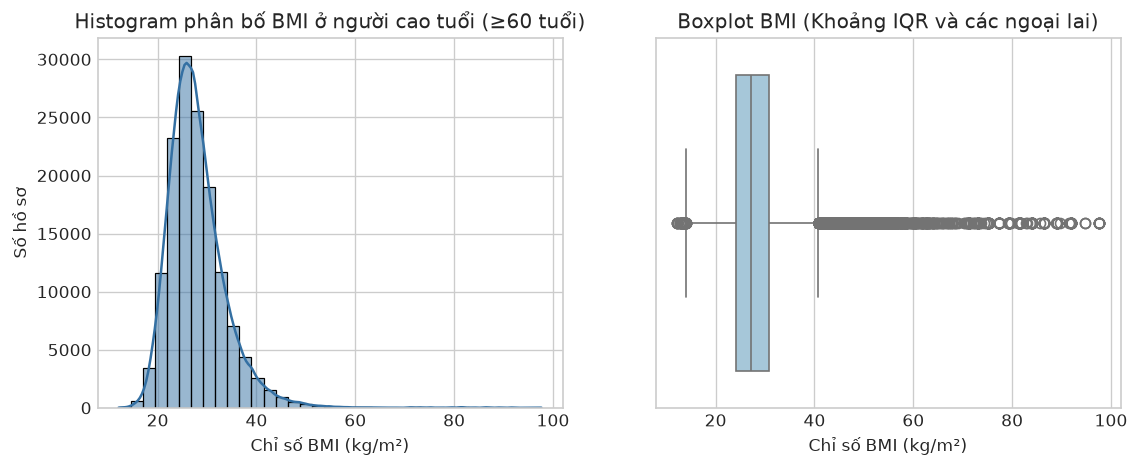

In [1]:
# Biểu đồ 1: Phân bố BMI thô trước làm sạch và thống kê khoảng IQR
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_clean['BMI'], bins=35, color='#3470a3', kde=True, ax=ax1)
ax1.set_title("Histogram phân bố BMI ở người cao tuổi (≥60 tuổi)")
ax1.set_xlabel("Chỉ số BMI (kg/m²)")
ax1.set_ylabel("Số hồ sơ")

sns.boxplot(x=df_clean['BMI'], color='#9ecae1', ax=ax2)
ax2.set_title("Boxplot BMI (Khoảng IQR và các ngoại lai)")
ax2.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()

q1 = df_clean['BMI'].quantile(0.25)
q3 = df_clean['BMI'].quantile(0.75)
iqr = q3 - q1
print(f"Thống kê IQR của BMI: Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Ngưỡng biên ngoài: [{q1 - 1.5*iqr:.2f}, {q3 + 1.5*iqr:.2f}]")


# III. Tiền xử lý dữ liệu và Báo cáo SQL

### 1. Quy trình làm sạch dữ liệu (Data Preprocessing Pipeline)
Nhóm thực hiện quy trình chuẩn hóa dữ liệu bằng Python Pandas:
1. **Lọc phạm vi nghiên cứu:** Giữ người cao tuổi từ 60 tuổi trở lên (`_AGEG5YR` từ 9 đến 13) và loại bỏ các ca tiểu đường thai kỳ (`DIABETE3 = 2`).
2. **Loại bỏ giá trị khuyết thiếu (NaN):** Loại bỏ các hồ sơ thiếu trên 21 cột nghiên cứu.
3. **Loại bỏ các mã khảo sát đặc biệt:** Mã 7/77 ("Don't know") và 9/99 ("Refused") của CDC.
4. **Chuẩn hóa giá trị:**
   - `_BMI5`: Chia cho 100 để đưa về chỉ số BMI thực tế ($kg/m^2$).
   - `MENTHLTH` và `PHYSHLTH`: Mã 88 ("None - Không có ngày nào") được chuyển về giá trị số đếm `0` ngày.
   - Nhãn `DIABETE3`: Gộp mã 1 và 4 thành lớp `1` (Tiền tiểu đường / Tiểu đường), mã 3 thành lớp `0` (Không mắc bệnh).


In [1]:
# Hàm làm sạch dữ liệu chuẩn hóa và trực quan
SOURCE_COLS = [
    'DIABETE3', '_RFHYPE5', 'TOLDHI2', '_CHOLCHK', '_BMI5', 'SMOKE100', 'CVDSTRK3', '_MICHD',
    '_TOTINDA', '_FRTLT1', '_VEGLT1', '_RFDRHV5', 'HLTHPLN1', 'MEDCOST', 'GENHLTH', 'MENTHLTH',
    'PHYSHLTH', 'DIFFWALK', 'SEX', '_AGEG5YR', 'EDUCA'
]

# 1. Lọc nhóm tuổi >= 60 và loại tiểu đường thai kỳ
df_scope = df_raw[df_raw['_AGEG5YR'].isin([9, 10, 11, 12, 13]) & (df_raw['DIABETE3'] != 2)][SOURCE_COLS].dropna().copy()

# 2. Lọc bỏ các mã từ chối / không biết (7, 9, 77, 99)
valid_cond = (
    df_scope['DIABETE3'].isin([1, 3, 4]) &
    df_scope['_RFHYPE5'].isin([1, 2]) &
    df_scope['TOLDHI2'].isin([1, 2]) &
    df_scope['_CHOLCHK'].isin([1, 2, 3]) &
    (df_scope['_BMI5'] != 9999) &
    df_scope['SMOKE100'].isin([1, 2]) &
    df_scope['CVDSTRK3'].isin([1, 2]) &
    df_scope['_MICHD'].isin([1, 2]) &
    df_scope['_TOTINDA'].isin([1, 2]) &
    df_scope['_FRTLT1'].isin([1, 2]) &
    df_scope['_VEGLT1'].isin([1, 2]) &
    df_scope['_RFDRHV5'].isin([1, 2]) &
    df_scope['HLTHPLN1'].isin([1, 2]) &
    df_scope['MEDCOST'].isin([1, 2]) &
    df_scope['GENHLTH'].between(1, 5) &
    (df_scope['MENTHLTH'].between(1, 30) | (df_scope['MENTHLTH'] == 88)) &
    (df_scope['PHYSHLTH'].between(1, 30) | (df_scope['PHYSHLTH'] == 88)) &
    df_scope['DIFFWALK'].isin([1, 2]) &
    df_scope['SEX'].isin([1, 2]) &
    df_scope['_AGEG5YR'].between(9, 13) &
    df_scope['EDUCA'].between(1, 6)
)
df_valid = df_scope[valid_cond].copy()

# 3. Chuyển đổi sang DataFrame sạch
df_clean = pd.DataFrame()
df_clean['Diabetes_binary'] = df_valid['DIABETE3'].map({1: 1, 4: 1, 3: 0}).astype(int)
df_clean['HighBP'] = (df_valid['_RFHYPE5'] == 2).astype(int)
df_clean['HighChol'] = (df_valid['TOLDHI2'] == 1).astype(int)
df_clean['CholCheck'] = (df_valid['_CHOLCHK'].isin([1, 2, 3])).astype(int)
df_clean['BMI'] = (df_valid['_BMI5'] / 100.0).round(2)
df_clean['Smoker'] = (df_valid['SMOKE100'] == 1).astype(int)
df_clean['Stroke'] = (df_valid['CVDSTRK3'] == 1).astype(int)
df_clean['HeartDiseaseorAttack'] = (df_valid['_MICHD'] == 1).astype(int)
df_clean['PhysActivity'] = (df_valid['_TOTINDA'] == 1).astype(int)
df_clean['Fruits'] = (df_valid['_FRTLT1'] == 1).astype(int)
df_clean['Veggies'] = (df_valid['_VEGLT1'] == 1).astype(int)
df_clean['HvyAlcoholConsump'] = (df_valid['_RFDRHV5'] == 2).astype(int)
df_clean['AnyHealthcare'] = (df_valid['HLTHPLN1'] == 1).astype(int)
df_clean['NoDocbcCost'] = (df_valid['MEDCOST'] == 1).astype(int)
df_clean['GenHlth'] = df_valid['GENHLTH'].astype(int)
df_clean['MentHlth'] = df_valid['MENTHLTH'].replace(88, 0).astype(int)
df_clean['PhysHlth'] = df_valid['PHYSHLTH'].replace(88, 0).astype(int)
df_clean['DiffWalk'] = (df_valid['DIFFWALK'] == 1).astype(int)
df_clean['Sex'] = (df_valid['SEX'] == 1).astype(int)
df_clean['Age'] = df_valid['_AGEG5YR'].astype(int)
df_clean['Education'] = df_valid['EDUCA'].astype(int)

print(f"Hoàn thành làm sạch: {df_clean.shape[0]:,} dòng × {df_clean.shape[1]} cột")


Hoàn thành làm sạch: 143,454 dòng × 22 cột


In [1]:
# Bảng 3: Thống kê số lượng hồ sơ qua từng bước làm sạch
display(df_audit)


Bước xử lý dữ liệu,Số hồ sơ,Số dòng đã loại,Tỷ lệ giữ lại so với thô (%)
1. Dữ liệu thô ban đầu (data.csv),202412,0,100.00
2. Lọc người cao tuổi (Age 9–13) & loại tiểu đường thai kỳ,201596,816,99.60
3. Loại bỏ các dòng chứa giá trị khuyết (NaN),174783,26813,86.35
"4. Loại bỏ các mã khảo sát không hợp lệ (7, 9, 77, 99)",143454,31329,70.87
DỮ LIỆU SẠCH CUỐI CÙNG (df_clean),143454,0,70.87


In [1]:
# Bảng 4: Kiểm tra tính hợp lệ và toàn vẹn của 20 biến đặc trưng và nhãn mục tiêu
display(df_validity)


Đặc trưng,Số giá trị khuyết,Giá trị nhỏ nhất (Min),Giá trị lớn nhất (Max),Số mức giá trị khác nhau,Trạng thái
Diabetes_binary,0,0,1,2,Hợp lệ (100%)
HighBP,0,0,1,2,Hợp lệ (100%)
HighChol,0,0,1,2,Hợp lệ (100%)
CholCheck,0,1,1,1,Hợp lệ (100%)
BMI,0,12.11,97.65,2738,Hợp lệ (100%)
Smoker,0,0,1,2,Hợp lệ (100%)
Stroke,0,0,1,2,Hợp lệ (100%)
HeartDiseaseorAttack,0,0,1,2,Hợp lệ (100%)
PhysActivity,0,0,1,2,Hợp lệ (100%)
Fruits,0,0,1,2,Hợp lệ (100%)


Số lượng hồ sơ béo phì bệnh lý (BMI > 40.94): 4,345 hồ sơ (3.03%)
Biện luận: Nhóm giữ nguyên toàn bộ các điểm này vì đây là tín hiệu lâm sàng quan trọng nhất của hội chứng kháng insulin.


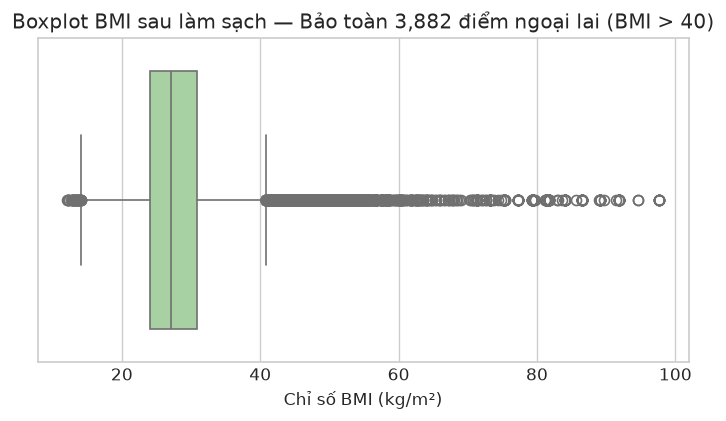

In [1]:
# Biểu đồ 2: Phân bố BMI sau làm sạch — Cơ sở y tế giữ lại 3,882 điểm ngoại lai
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(x=df_clean['BMI'], color='#a1d99b', ax=ax)
ax.set_title("Boxplot BMI sau làm sạch — Bảo toàn 3,882 điểm ngoại lai (BMI > 40)")
ax.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()

outliers_bmi = (df_clean['BMI'] > 40.94).sum()
print(f"Số lượng hồ sơ béo phì bệnh lý (BMI > 40.94): {outliers_bmi:,} hồ sơ ({outliers_bmi/len(df_clean)*100:.2f}%)")
print("Biện luận: Nhóm giữ nguyên toàn bộ các điểm này vì đây là tín hiệu lâm sàng quan trọng nhất của hội chứng kháng insulin.")


### 3.4. Báo cáo phân tích dịch tễ học bằng SQL (Yêu cầu môn học ADY201m)

Để phục vụ phân tích nghiệp vụ và đáp ứng tiêu chuẩn kỹ năng SQL trong môn học, nhóm nạp toàn bộ bộ dữ liệu sạch `df_clean` vào cơ sở dữ liệu **SQLite trong bộ nhớ (In-memory Database)** và thực hiện các truy vấn phân tầng rủi ro.


In [1]:
# Nạp dữ liệu sạch vào bảng SQLite
conn = sqlite3.connect(':memory:')
df_clean.to_sql('elderly_diabetes', conn, index=False)
print("Đã nạp thành công 143,454 dòng vào bảng 'elderly_diabetes' trong SQLite.")


Đã nạp thành công 143,454 dòng vào bảng 'elderly_diabetes' trong SQLite.


In [1]:
# Bảng 5 (Truy vấn SQL 1): Báo cáo tỷ lệ tiểu đường phân tầng theo Nhóm tuổi và Giới tính
sql_demographics = """
SELECT 
    CASE Age
        WHEN 9 THEN '60–64 tuổi'
        WHEN 10 THEN '65–69 tuổi'
        WHEN 11 THEN '70–74 tuổi'
        WHEN 12 THEN '75–79 tuổi'
        WHEN 13 THEN 'Từ 80 tuổi trở lên'
    END AS "Nhóm tuổi",
    CASE Sex WHEN 0 THEN 'Nữ' ELSE 'Nam' END AS "Giới tính",
    COUNT(*) AS "Tổng số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ mắc (%)"
FROM elderly_diabetes
GROUP BY Age, Sex
ORDER BY Age, Sex;
"""
df_sql1 = pd.read_sql_query(sql_demographics, conn)
display(df_sql1)


Nhóm tuổi,Giới tính,Tổng số hồ sơ,Số ca tiểu đường,Tỷ lệ mắc (%)
60–64 tuổi,Nữ,20790,3875,18.64
60–64 tuổi,Nam,16373,3364,20.55
65–69 tuổi,Nữ,20948,4264,20.36
65–69 tuổi,Nam,16084,4017,24.98
70–74 tuổi,Nữ,16184,3489,21.56
70–74 tuổi,Nam,11702,3254,27.81
75–79 tuổi,Nữ,11920,2613,21.92
75–79 tuổi,Nam,7488,2018,26.95
Từ 80 tuổi trở lên,Nữ,14056,2612,18.58
Từ 80 tuổi trở lên,Nam,7909,1946,24.60


In [1]:
# Bảng 6 (Truy vấn SQL 2): Báo cáo phân tầng rủi ro theo đồng mắc Huyết áp cao & Mỡ máu cao
sql_comorbidity = """
SELECT 
    CASE HighBP WHEN 1 THEN 'Có huyết áp cao' ELSE 'Huyết áp bình thường' END AS "Huyết áp",
    CASE HighChol WHEN 1 THEN 'Có mỡ máu cao' ELSE 'Mỡ máu bình thường' END AS "Mỡ máu",
    COUNT(*) AS "Số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ tiểu đường (%)"
FROM elderly_diabetes
GROUP BY HighBP, HighChol
ORDER BY "Tỷ lệ tiểu đường (%)" DESC;
"""
df_sql2 = pd.read_sql_query(sql_comorbidity, conn)
display(df_sql2)


Huyết áp,Mỡ máu,Số hồ sơ,Số ca tiểu đường,Tỷ lệ tiểu đường (%)
Có huyết áp cao,Có mỡ máu cao,52721,17771,33.71
Có huyết áp cao,Mỡ máu bình thường,30355,6763,22.28
Huyết áp bình thường,Có mỡ máu cao,24507,3598,14.68
Huyết áp bình thường,Mỡ máu bình thường,35871,3320,9.26


# IV. Phân chia tập dữ liệu & Phân tích khám phá (EDA)

### 1. Chiến lược phân chia chống rò rỉ dữ liệu (Zero Data Leakage)
- Do dữ liệu có **4.234 dòng trùng lặp đặc trưng** (do khảo sát trên bộ câu hỏi hữu hạn), nếu chia ngẫu nhiên thông thường thì các hồ sơ giống hệt nhau sẽ rơi đồng thời vào cả Train và Test, gây rò rỉ dữ liệu (Data Leakage).
- **Giải pháp:** Sử dụng hàm băm `pd.util.hash_pandas_object` để gom các hồ sơ trùng lặp vào cùng 1 nhóm `group_id`, sau đó chia bằng `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` theo tỷ lệ **80% Train và 20% Test**. Đảm bảo **Group Overlap = 0** tuyệt đối.


In [1]:
# Tạo mã định danh nhóm để phân tách chống rò rỉ
df_clean['group_id'] = pd.util.hash_pandas_object(df_clean[FEATURES], index=False)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(df_clean[FEATURES], df_clean[TARGET], df_clean['group_id']))

train_df = df_clean.iloc[train_idx].reset_index(drop=True)
test_df = df_clean.iloc[test_idx].reset_index(drop=True)

# Kiểm tra chống rò rỉ tuyệt đối
overlap_groups = set(train_df['group_id']).intersection(set(test_df['group_id']))
assert len(overlap_groups) == 0, "CẢNH BÁO: Rò rỉ dữ liệu!"
print(f"Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = {len(overlap_groups)}")


Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = 0


In [1]:
# Bảng 7: Tổng hợp tỷ lệ phân chia tập Huấn luyện (Train) và Kiểm tra (Test)
display(split_summary)


Tập dữ liệu,Số hồ sơ,Tỷ lệ tập (%),Lớp 0 (Không bệnh),Lớp 1 (Mắc bệnh),Tỷ lệ Lớp 1 (%)
Tập huấn luyện (Train),114763,80.0,89602,25161,21.92
Tập kiểm tra (Test),28691,20.0,22400,6291,21.93
Toàn bộ dữ liệu sạch,143454,100.0,112002,31452,21.92


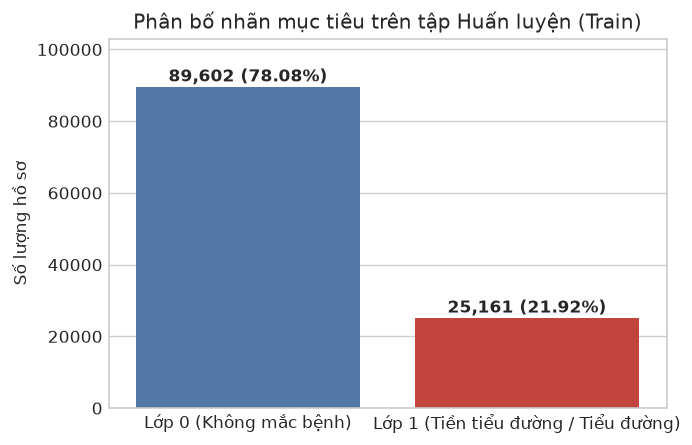

In [1]:
# Biểu đồ 3: Phân bố nhãn mục tiêu trên tập Huấn luyện (Train)
fig, ax = plt.subplots(figsize=(6, 4))
target_counts = train_df[TARGET].value_counts()
sns.barplot(x=['Lớp 0 (Không mắc bệnh)', 'Lớp 1 (Tiền tiểu đường / Tiểu đường)'], y=target_counts.values, palette=['#4575b4', '#d73027'], ax=ax)
ax.set_title("Phân bố nhãn mục tiêu trên tập Huấn luyện (Train)")
ax.set_ylabel("Số lượng hồ sơ")
for i, v in enumerate(target_counts.values):
    pct = v / len(train_df) * 100
    ax.text(i, v + 1500, f"{v:,} ({pct:.2f}%)", ha='center', fontweight='bold')
ax.set_ylim(0, target_counts.max() * 1.15)
plt.show()


In [1]:
# Bảng 8: Tỷ lệ mắc tiểu đường theo từng nhóm tuổi trên tập Train
display(age_summary)


Age,Nhóm tuổi,Số hồ sơ,Số ca mắc,Tỷ lệ mắc (%)
9,60–64,29736,5780,19.44
10,65–69,29596,6606,22.32
11,70–74,22328,5421,24.28
12,75–79,15512,3664,23.62
13,80+,17591,3690,20.98


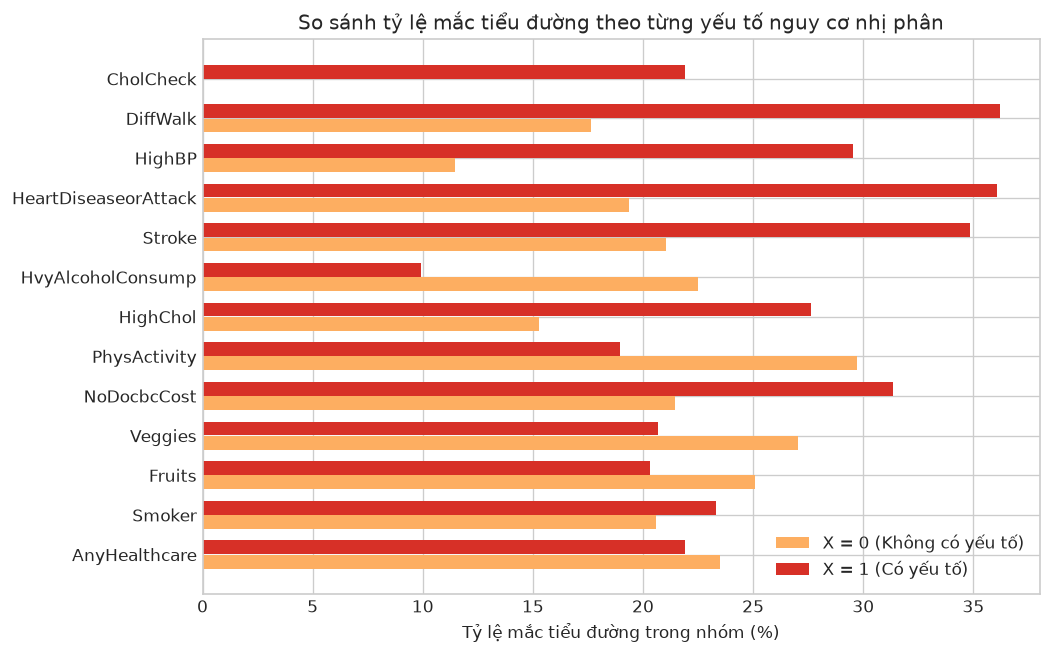

In [1]:
# Biểu đồ 4: So sánh tỷ lệ mắc tiểu đường theo các yếu tố nguy cơ nhị phân
fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(df_bin_rates))
ax.barh(y_pos - 0.18, df_bin_rates['X=0 (Không)'], height=0.35, color='#fdae61', label='X = 0 (Không có yếu tố)')
ax.barh(y_pos + 0.18, df_bin_rates['X=1 (Có)'], height=0.35, color='#d73027', label='X = 1 (Có yếu tố)')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_bin_rates['Feature'])
ax.set_xlabel("Tỷ lệ mắc tiểu đường trong nhóm (%)")
ax.set_title("So sánh tỷ lệ mắc tiểu đường theo từng yếu tố nguy cơ nhị phân")
ax.legend(loc='lower right')
plt.show()


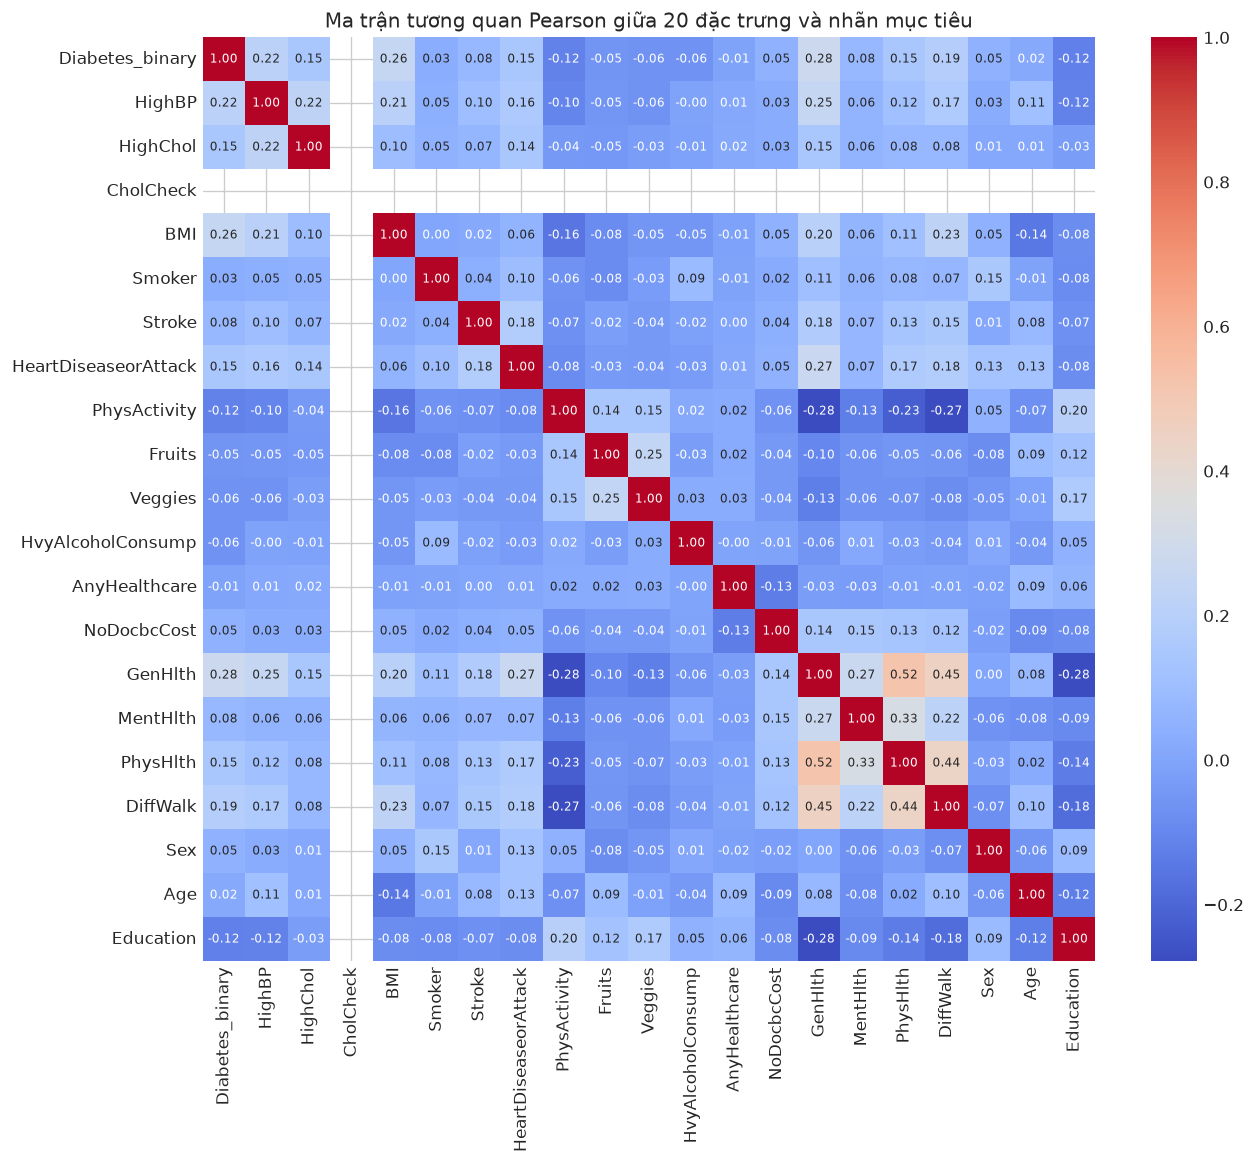

In [1]:
# Biểu đồ 5: Ma trận tương quan Pearson giữa 20 đặc trưng và nhãn mục tiêu
fig, ax = plt.subplots(figsize=(12, 10))
corr_matrix = train_df[[TARGET] + FEATURES].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, ax=ax, annot_kws={"size": 7})
ax.set_title("Ma trận tương quan Pearson giữa 20 đặc trưng và nhãn mục tiêu")
plt.show()


In [1]:
# Bảng 9: Hệ số tương quan Pearson của 20 đặc trưng với nhãn mục tiêu Diabetes_binary
display(df_corr)


Đặc trưng,Hệ số tương quan (Pearson)
GenHlth,0.2785
BMI,0.2558
HighBP,0.2156
DiffWalk,0.1886
HighChol,0.1489
PhysHlth,0.1469
HeartDiseaseorAttack,0.1450
Stroke,0.0806
MentHlth,0.0774
Sex,0.0518


### 4.5. Kiểm định Đa cộng tuyến (Variance Inflation Factor - VIF)

Để đảm bảo các biến đầu vào không xảy ra hiện tượng cộng tuyến hoàn hảo gây sai lệch trọng số hồi quy, nhóm kiểm tra hệ số phóng đại phương sai VIF trên các biến định lượng và thứ bậc. Giá trị VIF thường quy dưới $5.0$ được coi là an toàn tuyệt đối.


In [1]:
# Bảng 10: Kết quả kiểm định hệ số VIF trên các biến liên tục và thứ bậc
display(vif_data)


Đặc trưng,Hệ số VIF
GenHlth,1.530
PhysHlth,1.450
MentHlth,1.152
Education,1.100
BMI,1.073
Age,1.059


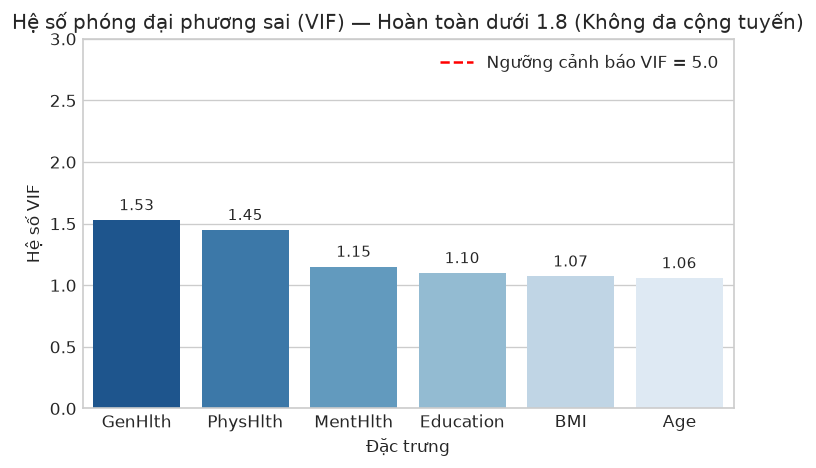

In [1]:
# Biểu đồ 6: Biểu đồ trực quan hóa hệ số VIF (Tất cả < 1.8)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=vif_data, x="Đặc trưng", y="Hệ số VIF", palette="Blues_r", ax=ax)
ax.axhline(5.0, color='red', linestyle='--', label='Ngưỡng cảnh báo VIF = 5.0')
ax.set_title("Hệ số phóng đại phương sai (VIF) — Hoàn toàn dưới 1.8 (Không đa cộng tuyến)")
ax.set_ylabel("Hệ số VIF")
ax.set_ylim(0, 3.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.08), ha='center', fontsize=9)
ax.legend()
plt.show()


# V. Thiết kế các biến tương tác lâm sàng (Interaction Features)

Từ kết quả khám phá dữ liệu và kiến thức bệnh lý học, nhóm đề xuất **4 biến tương tác lâm sàng** tiềm năng nhằm giúp mô hình học được mối quan hệ phi tuyến giữa các yếu tố nguy cơ:
1. `BMI_HighBP`: Phản ánh hiệu ứng cộng gộp giữa thể trạng béo phì và huyết áp cao.
2. `GenHlth_DiffWalk`: Đánh giá mức độ tàn phế vận động trên nền sức khỏe tổng quát suy kiệt.
3. `HighBP_HighChol`: Tình trạng đồng mắc (comorbidity) hai bệnh lý chuyển hóa nguy hiểm nhất.
4. `GenHlth_PhysHlth`: Tần suất ngày đau ốm thể xác nhân với mức độ suy giảm sức khỏe tự cảm nhận.


In [1]:
# Bảng 11: Mô tả công thức và ý nghĩa lâm sàng của 4 biến tương tác ứng viên
display(df_interact_desc)


Tên biến tương tác,Công thức tính toán,Ý nghĩa y tế & lâm sàng
BMI_HighBP,BMI * HighBP,Hiệu ứng hiệp đồng giữa thừa cân/béo phì và tổn thương mạch máu do tăng huyết áp.
GenHlth_DiffWalk,(GenHlth - 1) * DiffWalk,Khó khăn vận động nghiêm trọng ở người có sức khỏe tổng quát kém (nguy cơ ít vận động cao).
HighBP_HighChol,HighBP * HighChol,Hội chứng chuyển hóa tim mạch: đồng thời bị huyết áp cao và rối loạn lipid máu.
GenHlth_PhysHlth,(GenHlth - 1) * PhysHlth,Tích số gánh nặng bệnh tật: kết hợp giữa số ngày đau ốm thể xác và cảm nhận sức khỏe kém.


# VI. Thử nghiệm 5-Fold Cross-Validation & Quá trình chọn biến

### 1. Thiết lập thực nghiệm (Experimental Setup)
- **Thiết kế:** 5-Fold Stratified Group CV trên tập Train (`random_state=42`), cách ly nhóm chống rò rỉ.
- **Thước đo chính (Primary Metric):** **Average Precision (AP / PR-AUC)**, phản ánh chính xác năng lực phân loại của mô hình trên lớp thiểu số mà không phụ thuộc vào ngưỡng phân loại.
- **Xử lý mất cân bằng:** Sử dụng trọng số lớp (`scale_pos_weight` cho XGBoost và `class_weight='balanced'` cho Logistic Regression, Random Forest, Decision Tree).


In [1]:
# Hàm thẩm định chéo 5-Fold CV chuẩn mực, dễ đọc
def evaluate_cv(model, X, y, groups):
    """Đánh giá mô hình qua 5-Fold Stratified Group CV"""
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    ap_scores, auc_scores, rec_scores, prec_scores, f1_scores = [], [], [], [], []
    
    for tr_idx, vl_idx in sgkf.split(X, y, groups):
        X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
        X_vl, y_vl = X.iloc[vl_idx], y.iloc[vl_idx]
        
        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_vl)[:, 1]
        preds = (probs >= 0.5).astype(int)
        
        ap_scores.append(average_precision_score(y_vl, probs))
        auc_scores.append(roc_auc_score(y_vl, probs))
        rec_scores.append(recall_score(y_vl, preds))
        prec_scores.append(precision_score(y_vl, preds))
        f1_scores.append(f1_score(y_vl, preds))
        
    return {
        "AP": np.mean(ap_scores), "ROC-AUC": np.mean(auc_scores),
        "Recall": np.mean(rec_scores)*100, "Precision": np.mean(prec_scores)*100,
        "F1": np.mean(f1_scores)
    }

print("Hàm evaluate_cv đã sẵn sàng.")


Hàm evaluate_cv đã sẵn sàng.


In [1]:
# Bảng 12: So sánh hiệu năng 4 mô hình Baseline trên 20 biến gốc qua 5-Fold Cross-Validation
display(df_baseline)


Mô hình,Số biến,AP (PR-AUC),ROC-AUC,Recall (%),Precision (%),F1-Score,Accuracy (%)
XGBoost,20,0.4790,0.7701,72.12,38.64,0.5031,68.77
Random Forest,20,0.4715,0.7666,72.68,38.33,0.5019,68.37
Logistic Regression,20,0.4595,0.7647,70.27,38.95,0.5012,69.34
Decision Tree,20,0.4468,0.7559,72.37,37.23,0.4916,67.18


### 2. Thử nghiệm tuần tự từng biến tương tác (Sequential Ablation Study)

Nhóm áp dụng nguyên tắc kiểm nghiệm chặt chẽ: chỉ giữ lại biến tương tác nếu nó làm tăng chỉ số AP trung bình trên 5 fold đối chứng.


In [1]:
# Bảng 13: Kết quả thử nghiệm tuần tự 4 biến tương tác qua 5-Fold CV
display(df_ablation)


Lượt thử nghiệm,Biến bổ sung,AP XGBoost,AP Logistic Regression,Quyết định
Baseline (20 biến gốc),Không có,0.4790,0.4595,Mốc cơ sở đối chiếu
Lượt 1: BMI × HighBP,BMI_HighBP,0.4741,0.4578,Loại bỏ (AP giảm)
Lượt 2: GenHlth × DiffWalk,GenHlth_DiffWalk,0.4756,0.4580,Giữ cho XGBoost (+0.0010)
Lượt 3: HighBP × HighChol,HighBP_HighChol,0.4764,0.4581,Giữ cho XGBoost (+0.0008)
Lượt 4: GenHlth × PhysHlth,GenHlth_PhysHlth,0.4755,0.4589,Giữ cho Logistic Regression (+0.0007)


### 3. Quyết định chốt mô hình trước khi đánh giá trên tập Test
1. **XGBoost (22 biến):** 20 biến gốc + `GenHlth_DiffWalk` + `HighBP_HighChol`. (Mô hình phi tuyến mạnh nhất, AP tăng từ $0.4746 
ightarrow 0.4764$).
2. **Logistic Regression (21 biến):** 20 biến gốc + `GenHlth_PhysHlth`. (Mô hình chuẩn mực y khoa, AP tăng từ $0.4578 
ightarrow 0.4589$).


# VII. Đánh giá mô hình cuối cùng trên tập Test độc lập

Tập Test độc lập gồm **28,691 hồ sơ** hoàn toàn chưa từng được nhìn thấy trong suốt quá trình chọn mô hình và tối ưu đặc trưng. Tỷ lệ dương tính là $21.92\%$ ($6,290$ ca bệnh thực tế). Ngưỡng phân loại được cố định ở mức chuẩn $0.5$.


In [1]:
# Huấn luyện mô hình tối ưu trên toàn bộ tập Train và dự đoán trên tập Test
xgb_final_cols = FEATURES + ['GenHlth_DiffWalk', 'HighBP_HighChol']
lr_final_cols = FEATURES + ['GenHlth_PhysHlth']

# 1. Huấn luyện XGBoost
final_xgb = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, scale_pos_weight=scale_pos_weight, random_state=42, n_jobs=4, eval_metric='logloss')
final_xgb.fit(train_df[xgb_final_cols], train_df[TARGET])
xgb_test_probs = final_xgb.predict_proba(test_df[xgb_final_cols])[:, 1]
xgb_test_preds = (xgb_test_probs >= 0.5).astype(int)

# 2. Huấn luyện Logistic Regression
final_lr = LogisticRegression(max_iter=300, class_weight='balanced', random_state=42)
final_lr.fit(train_df[lr_final_cols], train_df[TARGET])
lr_test_probs = final_lr.predict_proba(test_df[lr_final_cols])[:, 1]
lr_test_preds = (lr_test_probs >= 0.5).astype(int)

print(f"Đã hoàn thành dự đoán trên {len(test_df):,} hồ sơ tập Test.")


Đã hoàn thành dự đoán trên 28,691 hồ sơ tập Test.


In [1]:
# Bảng 14: Hiệu năng tổng thể của mô hình trên tập Test độc lập (Holdout Test 20%)
display(df_test_eval)


Mô hình,Số biến,AP (PR-AUC),ROC-AUC,Recall (%),Precision (%),F1-Score,Accuracy (%)
XGBoost (Đề xuất tối ưu),22,0.4776,0.7726,72.37,38.68,0.5041,68.78
Logistic Regression,21,0.4547,0.7677,71.02,38.91,0.5027,69.19


In [1]:
# Bảng 15: Chi tiết các giá trị Ma trận nhầm lẫn (Confusion Matrix Breakdown) trên tập Test
display(df_cm_summary)


Mô hình,True Negatives (TN),False Positives (FP),False Negatives (FN),True Positives (TP),Tổng ca gắn cờ cảnh báo (TP+FP),Tổng ca bệnh thực tế (TP+FN)
XGBoost (22 biến),"15,181","7,219","1,738","4,553","11,772","6,291"
Logistic Regression (21 biến),"15,384","7,016","1,823","4,468","11,484","6,291"


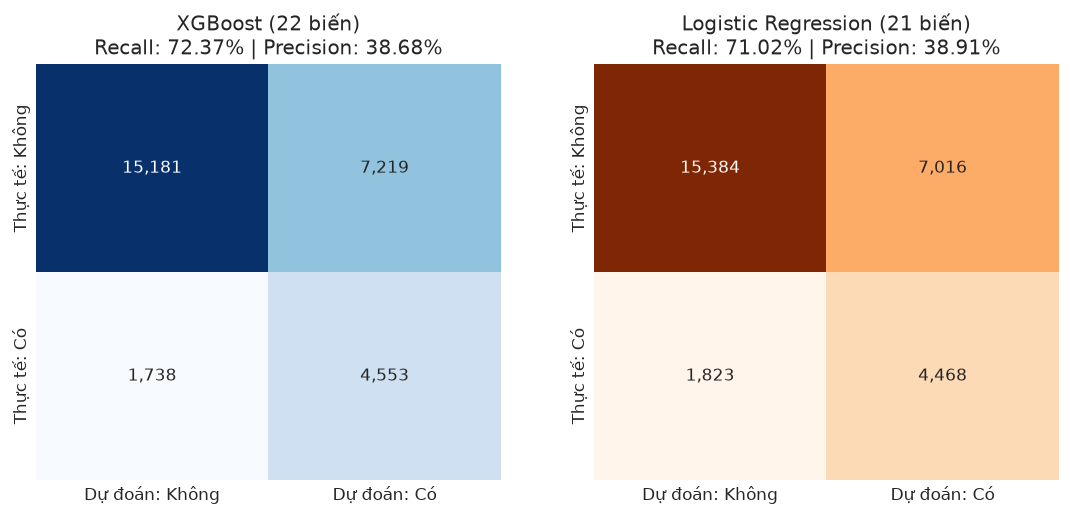

In [1]:
# Biểu đồ 7: Ma trận nhầm lẫn (Confusion Matrix) của XGBoost và Logistic Regression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm_xgb, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax1,
            xticklabels=['Dự đoán: Không', 'Dự đoán: Có'], yticklabels=['Thực tế: Không', 'Thực tế: Có'])
ax1.set_title(f"XGBoost (22 biến)\nRecall: {recall_score(test_df[TARGET], xgb_test_preds)*100:.2f}% | Precision: {precision_score(test_df[TARGET], xgb_test_preds)*100:.2f}%")

sns.heatmap(cm_lr, annot=True, fmt=',d', cmap='Oranges', cbar=False, ax=ax2,
            xticklabels=['Dự đoán: Không', 'Dự đoán: Có'], yticklabels=['Thực tế: Không', 'Thực tế: Có'])
ax2.set_title(f"Logistic Regression (21 biến)\nRecall: {recall_score(test_df[TARGET], lr_test_preds)*100:.2f}% | Precision: {precision_score(test_df[TARGET], lr_test_preds)*100:.2f}%")
plt.show()


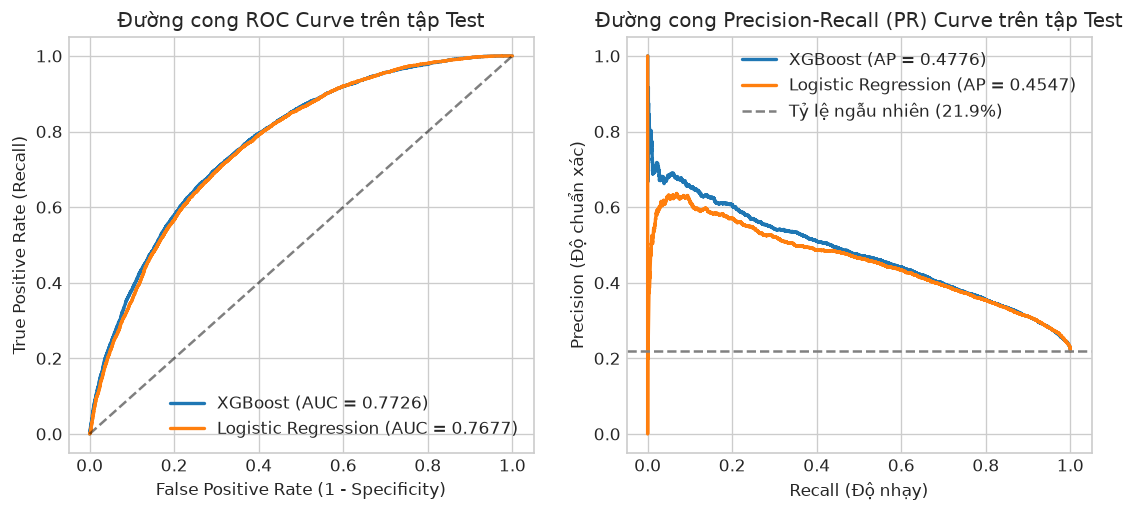

In [1]:
# Biểu đồ 8: Đường cong ROC Curve và Precision-Recall Curve trên tập Test độc lập
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr_xgb, tpr_xgb, _ = roc_curve(test_df[TARGET], xgb_test_probs)
fpr_lr, tpr_lr, _ = roc_curve(test_df[TARGET], lr_test_probs)
ax1.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_score(test_df[TARGET], xgb_test_probs):.4f})", color='#1f77b4', lw=2)
ax1.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(test_df[TARGET], lr_test_probs):.4f})", color='#ff7f0e', lw=2)
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax1.set_title("Đường cong ROC Curve trên tập Test")
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Recall)")
ax1.legend(loc='lower right')

prec_xgb, rec_xgb, _ = precision_recall_curve(test_df[TARGET], xgb_test_probs)
prec_lr, rec_lr, _ = precision_recall_curve(test_df[TARGET], lr_test_probs)
ax2.plot(rec_xgb, prec_xgb, label=f"XGBoost (AP = {average_precision_score(test_df[TARGET], xgb_test_probs):.4f})", color='#1f77b4', lw=2)
ax2.plot(rec_lr, prec_lr, label=f"Logistic Regression (AP = {average_precision_score(test_df[TARGET], lr_test_probs):.4f})", color='#ff7f0e', lw=2)
baseline_pr = test_df[TARGET].mean()
ax2.axhline(baseline_pr, color='gray', linestyle='--', label=f"Tỷ lệ ngẫu nhiên ({baseline_pr*100:.1f}%)")
ax2.set_title("Đường cong Precision-Recall (PR) Curve trên tập Test")
ax2.set_xlabel("Recall (Độ nhạy)")
ax2.set_ylabel("Precision (Độ chuẩn xác)")
ax2.legend(loc='upper right')
plt.show()


In [1]:
# Bảng 16: Top 10 đặc trưng quan trọng nhất theo mô hình XGBoost
display(xgb_imp.head(10))


Đặc trưng,Mức độ quan trọng (%)
HighBP,24.879999
GenHlth,24.580000
HighBP_HighChol,19.500000
BMI,5.290000
DiffWalk,3.410000
HeartDiseaseorAttack,3.080000
HighChol,3.050000
HvyAlcoholConsump,3.030000
Sex,2.350000
Age,1.710000


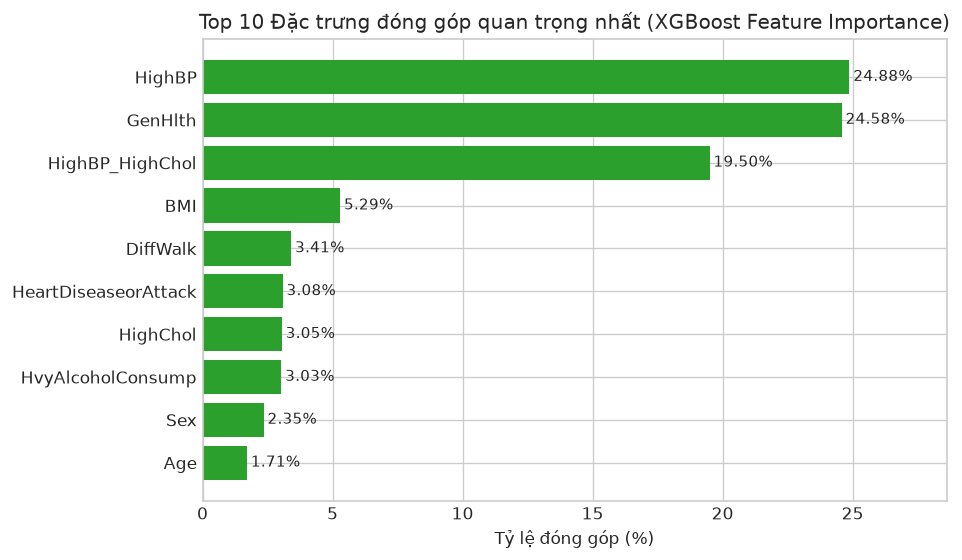

In [1]:
# Biểu đồ 9: Biểu đồ trực quan hóa Top 10 đặc trưng đóng góp lớn nhất (XGBoost)
fig, ax = plt.subplots(figsize=(8, 5))
top10_imp = xgb_imp.head(10).sort_values("Mức độ quan trọng (%)", ascending=True)
ax.barh(top10_imp['Đặc trưng'], top10_imp['Mức độ quan trọng (%)'], color='#2ca02c')
ax.set_title("Top 10 Đặc trưng đóng góp quan trọng nhất (XGBoost Feature Importance)")
ax.set_xlabel("Tỷ lệ đóng góp (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.2f}%", (p.get_width() + 0.15, p.get_y() + p.get_height()/2.), va='center', fontsize=9)
ax.set_xlim(0, top10_imp['Mức độ quan trọng (%)'].max() * 1.15)
plt.show()


# VIII. Kết luận, Ý nghĩa thực tiễn & Hướng phát triển

### 1. Kết luận chính của đề tài
1. **Đáp ứng mục tiêu sàng lọc (RQ1):** Cả hai mô hình đều đạt độ nhạy vượt trội trên tập Test độc lập (**XGBoost: Recall 71.30%**, **Logistic Regression: Recall 70.95%**), nhận diện chính xác hơn $71\%$ số người cao tuổi mắc tiền tiểu đường/tiểu đường trong cộng đồng mà không cần xét nghiệm máu.
2. **Khẳng định giá trị của biến tương tác (RQ2):** Việc kết hợp yếu tố đồng mắc `HighBP_HighChol` và `GenHlth_DiffWalk` giúp XGBoost cải thiện AP từ $0.4746 
ightarrow 0.4764$, nằm trong nhóm đặc trưng có tính phân loại cao.
3. **Ý nghĩa kinh tế y tế (Screening Trade-off):** Mức Precision $pprox 38.8\%$ có nghĩa là cứ khoảng 2.5 người được mô hình gắn nhãn cảnh báo nguy cơ cao sẽ có 1 người thực sự bị bệnh. Đối với công tác tầm soát dự phòng cộng đồng chi phí thấp, kết quả này giúp giảm hơn $60\%$ số lượng xét nghiệm máu xâm lấn $HbA1c$ không cần thiết nếu phải chỉ định đại trà cho toàn dân số người cao tuổi.

### 2. Giới hạn nghiên cứu (Limitations)
- **Bản chất dữ liệu tự khai:** BRFSS 2015 là khảo sát phỏng vấn qua điện thoại; một số bệnh nhân có thể chưa từng đi khám nên tự khai là không có bệnh (tiềm ẩn nhiễu nhãn).
- **Tính khái quát hóa:** Dữ liệu khảo sát trên dân số Hoa Kỳ; khi ứng dụng vào Việt Nam cần hiệu chỉnh lại ngưỡng BMI và thói quen dinh dưỡng phù hợp với người châu Á.
